# 05 - Temporal Movement Analysis

## Objective

Analyze how selected joint angles change across sampled video frames.

## Tasks

1. Load the joint-angle dataset.
2. Select an exercise video.
3. Sort its frames in temporal order.
4. Visualize elbow and knee angle changes.
5. Examine missing angle values and movement patterns.

## Limitation

Only five frames were sampled per video in the current dataset. Therefore, this analysis provides a sparse view of movement and is not sufficient for reliable repetition counting or validated injury-risk prediction.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project folders
project_folder = Path("..")
output_folder = project_folder / "outputs"

# Load the joint-angle dataset
angles_path = output_folder / "joint_angles_all.csv"

print("Looking for dataset:", angles_path.resolve())
print("File exists:", angles_path.exists())

Looking for dataset: C:\athlete-performance-injury-risk\outputs\joint_angles_all.csv
File exists: True


In [3]:
angles_df = pd.read_csv(angles_path)

print("Dataset shape:", angles_df.shape)
print("\nAvailable columns:")
print(angles_df.columns.tolist())

display(angles_df.head())

Dataset shape: (3005, 9)

Available columns:
['video_name', 'category', 'frame_number', 'left_elbow_angle', 'right_elbow_angle', 'left_knee_angle', 'right_knee_angle', 'left_hip_angle', 'right_hip_angle']


,video_name,category,frame_number,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,0,136.532366,NaN,76.303009,61.115009,167.502841,154.760229
1,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,29,119.236965,NaN,35.128447,NaN,71.053439,NaN
2,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,59,166.130163,NaN,28.303478,NaN,52.390251,NaN
3,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,89,142.758576,NaN,51.370671,NaN,124.260108,NaN
4,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,119,141.210317,NaN,51.363290,NaN,61.971812,NaN


In [4]:
# Count videos in each exercise category
video_counts = (
    angles_df.groupby("category")["video_name"]
    .nunique()
    .sort_values(ascending=False)
)

display(video_counts)

print("\nTotal unique videos:", angles_df["video_name"].nunique())

category
barbell biceps curl    61
bench press            60
push-up                56
tricep Pushdown        50
lat pulldown           48
lateral raise          37
incline bench press    33
deadlift               32
squat                  29
chest fly machine      28
pull Up                26
leg extension          23
leg raises             21
t bar row              21
tricep dips            20
hammer curl            19
hip thrust             18
shoulder press         17
romanian deadlift      14
russian twist          13
decline bench press    12
plank                   7
Name: video_name, dtype: int64


Total unique videos: 645


In [5]:
# Find videos belonging to the biceps curl category
biceps_videos = (
    angles_df.loc[
        angles_df["category"].str.contains("biceps curl", case=False, na=False),
        "video_name"
    ]
    .drop_duplicates()
    .tolist()
)

print("Biceps curl videos found:", len(biceps_videos))

for i, video in enumerate(biceps_videos[:10], start=1):
    print(f"{i}. {video}")

Biceps curl videos found: 61
1. barbell biceps curl_1.mp4
2. barbell biceps curl_10.mp4
3. barbell biceps curl_11.mp4
4. barbell biceps curl_12.mp4
5. barbell biceps curl_13.mp4
6. barbell biceps curl_14.mp4
7. barbell biceps curl_15.mp4
8. barbell biceps curl_16.mp4
9. barbell biceps curl_17.mp4
10. barbell biceps curl_18.mp4


In [6]:
if not biceps_videos:
    print("No biceps curl videos found. Check the category names.")
else:
    selected_video = biceps_videos[0]

    video_df = angles_df[
        angles_df["video_name"] == selected_video
    ].copy()

    video_df = video_df.sort_values("frame_number")

    print("Selected video:", selected_video)
    print("Exercise:", video_df["category"].iloc[0])
    print("Number of sampled frames:", len(video_df))

    display(
        video_df[
            [
                "frame_number",
                "left_elbow_angle",
                "right_elbow_angle",
                "left_knee_angle",
                "right_knee_angle",
            ]
        ]
    )

Selected video: barbell biceps curl_1.mp4
Exercise: barbell biceps curl
Number of sampled frames: 5


,frame_number,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle
5,0,6.987998,22.721101,170.063252,175.538028
6,28,44.710857,68.045829,NaN,168.955132
7,56,160.578317,165.659820,NaN,NaN
8,84,163.064091,165.151458,NaN,NaN
9,113,5.200463,19.162531,NaN,NaN


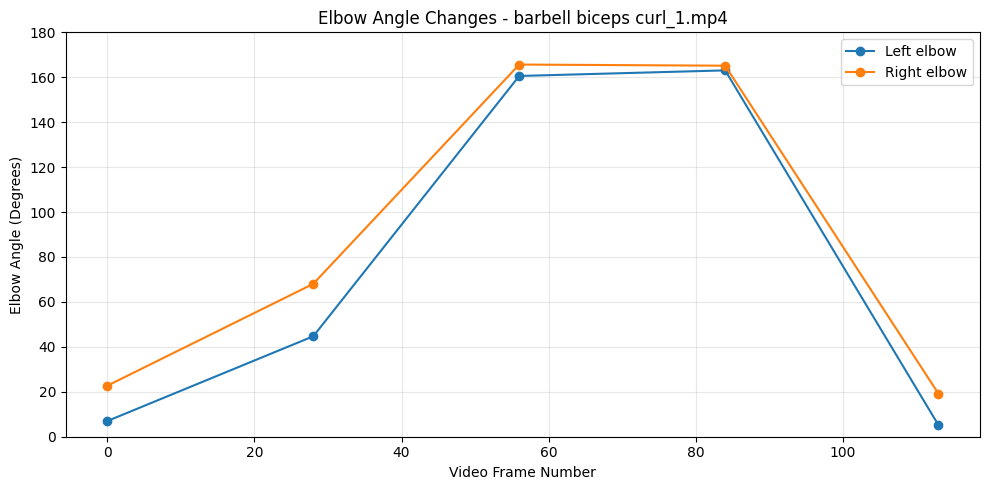

Graph saved to: C:\athlete-performance-injury-risk\outputs\biceps_curl_elbow_temporal.png


In [7]:
# Plot elbow angles across sampled frames
plt.figure(figsize=(10, 5))

plt.plot(
    video_df["frame_number"],
    video_df["left_elbow_angle"],
    marker="o",
    label="Left elbow"
)

plt.plot(
    video_df["frame_number"],
    video_df["right_elbow_angle"],
    marker="o",
    label="Right elbow"
)

plt.title(f"Elbow Angle Changes - {selected_video}")
plt.xlabel("Video Frame Number")
plt.ylabel("Elbow Angle (Degrees)")
plt.ylim(0, 180)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph
temporal_plot_path = output_folder / "biceps_curl_elbow_temporal.png"
plt.savefig(temporal_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", temporal_plot_path.resolve())

In [8]:
angle_columns = ["left_elbow_angle", "right_elbow_angle"]

for column in angle_columns:
    change_column = column.replace("_angle", "_change")
    video_df[change_column] = video_df[column].diff()

display(
    video_df[
        [
            "frame_number",
            "left_elbow_angle",
            "left_elbow_change",
            "right_elbow_angle",
            "right_elbow_change",
        ]
    ].round(2)
)

,frame_number,left_elbow_angle,left_elbow_change,right_elbow_angle,right_elbow_change
5,0,6.99,NaN,22.72,NaN
6,28,44.71,37.72,68.05,45.32
7,56,160.58,115.87,165.66,97.61
8,84,163.06,2.49,165.15,-0.51
9,113,5.20,-157.86,19.16,-145.99


In [9]:
temporal_output_path = output_folder / "biceps_curl_temporal_analysis.csv"

video_df.to_csv(temporal_output_path, index=False)

print("Temporal analysis saved to:")
print(temporal_output_path.resolve())

Temporal analysis saved to:
C:\athlete-performance-injury-risk\outputs\biceps_curl_temporal_analysis.csv


In [10]:
angle_columns = [
    "left_elbow_angle",
    "right_elbow_angle",
    "left_knee_angle",
    "right_knee_angle",
    "left_hip_angle",
    "right_hip_angle",
]

# Sort frames within each video
angles_df = angles_df.sort_values(
    ["video_name", "frame_number"]
).copy()

# Calculate change between consecutive sampled frames
for column in angle_columns:
    change_column = column.replace("_angle", "_change")

    angles_df[change_column] = (
        angles_df.groupby("video_name")[column].diff()
    )

display(angles_df.head(10))

,video_name,category,frame_number,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle,left_elbow_change,right_elbow_change,left_knee_change,right_knee_change,left_hip_change,right_hip_change
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,0,136.532366,NaN,76.303009,61.115009,167.502841,154.760229,NaN,NaN,NaN,NaN,NaN,NaN
1,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,29,119.236965,NaN,35.128447,NaN,71.053439,NaN,-17.295402,NaN,-41.174562,NaN,-96.449401,NaN
2,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,59,166.130163,NaN,28.303478,NaN,52.390251,NaN,46.893198,NaN,-6.824969,NaN,-18.663189,NaN
3,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,89,142.758576,NaN,51.370671,NaN,124.260108,NaN,-23.371587,NaN,23.067192,NaN,71.869858,NaN
4,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,119,141.210317,NaN,51.363290,NaN,61.971812,NaN,-1.548260,NaN,-0.007381,NaN,-62.288296,NaN
5,barbell biceps curl_1.mp4,barbell biceps curl,0,6.987998,22.721101,170.063252,175.538028,176.429518,173.544925,NaN,NaN,NaN,NaN,NaN,NaN
6,barbell biceps curl_1.mp4,barbell biceps curl,28,44.710857,68.045829,NaN,168.955132,175.229511,173.427927,37.722859,45.324728,NaN,-6.582896,-1.200006,-0.116998
7,barbell biceps curl_1.mp4,barbell biceps curl,56,160.578317,165.659820,NaN,NaN,177.455960,172.906028,115.867459,97.613991,NaN,NaN,2.226449,-0.521898
8,barbell biceps curl_1.mp4,barbell biceps curl,84,163.064091,165.151458,NaN,NaN,175.692203,174.740348,2.485774,-0.508362,NaN,NaN,-1.763758,1.834320
9,barbell biceps curl_1.mp4,barbell biceps curl,113,5.200463,19.162531,NaN,NaN,NaN,NaN,-157.863628,-145.988927,NaN,NaN,NaN,NaN


In [11]:
features_path = output_folder / "temporal_movement_features.csv"

angles_df.to_csv(features_path, index=False)

print("Temporal movement features saved to:")
print(features_path.resolve())
print("Dataset shape:", angles_df.shape)

Temporal movement features saved to:
C:\athlete-performance-injury-risk\outputs\temporal_movement_features.csv
Dataset shape: (3005, 15)


In [12]:
# Identify angle and angle-change columns
feature_columns = [
    col for col in angles_df.columns
    if col.endswith("_angle") or col.endswith("_change")
]

# Count valid and missing values
quality_summary = pd.DataFrame({
    "valid_values": angles_df[feature_columns].count(),
    "missing_values": angles_df[feature_columns].isna().sum(),
    "missing_percent": (
        angles_df[feature_columns].isna().mean() * 100
    ).round(2)
})

display(quality_summary)

,valid_values,missing_values,missing_percent
left_elbow_angle,2350,655,21.80
right_elbow_angle,2210,795,26.46
left_knee_angle,1262,1743,58.00
right_knee_angle,1280,1725,57.40
left_hip_angle,1844,1161,38.64
right_hip_angle,1770,1235,41.10
left_elbow_change,1693,1312,43.66
right_elbow_change,1563,1442,47.99
left_knee_change,798,2207,73.44
right_knee_change,807,2198,73.14


In [13]:
angle_columns = [
    "left_elbow_angle",
    "right_elbow_angle",
    "left_knee_angle",
    "right_knee_angle",
    "left_hip_angle",
    "right_hip_angle",
]

change_columns = [
    col for col in angles_df.columns
    if col.endswith("_change")
]

video_features = angles_df.groupby(
    ["video_name", "category"]
).agg(
    sampled_frames=("frame_number", "count"),
    **{
        f"{col}_mean": (col, "mean")
        for col in angle_columns
    },
    **{
        f"{col}_mean": (col, "mean")
        for col in change_columns
    }
).reset_index()

display(video_features.head())
print("Videos summarized:", len(video_features))

,video_name,category,sampled_frames,left_elbow_angle_mean,right_elbow_angle_mean,left_knee_angle_mean,right_knee_angle_mean,left_hip_angle_mean,right_hip_angle_mean,left_elbow_change_mean,right_elbow_change_mean,left_knee_change_mean,right_knee_change_mean,left_hip_change_mean,right_hip_change_mean
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,5,141.173677,NaN,48.493779,61.115009,95.435690,154.760229,1.169488,NaN,-6.234930,NaN,-26.382757,NaN
1,barbell biceps curl_1.mp4,barbell biceps curl,5,76.108345,88.148148,170.063252,172.246580,176.201798,173.654807,-0.446884,-0.889642,NaN,-6.582896,-0.245772,0.398474
2,barbell biceps curl_10.mp4,barbell biceps curl,5,99.887612,105.472417,NaN,NaN,176.069324,175.407887,-37.302291,-35.019579,NaN,NaN,NaN,NaN
3,barbell biceps curl_11.mp4,barbell biceps curl,5,111.350837,NaN,166.629666,NaN,172.010563,NaN,-2.333987,NaN,-0.393170,NaN,0.306884,NaN
4,barbell biceps curl_12.mp4,barbell biceps curl,5,78.654110,92.070697,179.202280,179.089187,174.263761,173.333825,-41.357766,-41.325086,0.181597,0.393909,0.111265,0.427393


Videos summarized: 645


In [14]:
video_features_path = output_folder / "video_level_movement_features.csv"

video_features.to_csv(video_features_path, index=False)

print("Video-level features saved to:")
print(video_features_path.resolve())

print("Number of videos:", len(video_features))
print("Number of features:", video_features.shape[1] - 2)

Video-level features saved to:
C:\athlete-performance-injury-risk\outputs\video_level_movement_features.csv
Number of videos: 645
Number of features: 13


## Results and Observations

- Joint-angle features and consecutive sampled-frame angle differences were calculated for 3,005 frames across 645 videos.
- Temporal features were generated separately for each video.
- Video-level mean features were created to summarize the sampled movement patterns.
- Elbow angles had fewer missing values than knee angles in this dataset.
- Angle-change features had additional missing values because they require valid measurements in consecutive sampled frames.

## Limitations

- Only five frames were sampled per video, providing a sparse representation of movement.
- The angle differences are not angular velocity because elapsed time was not incorporated.
- Missing landmarks can affect joint-angle availability and feature reliability.
- Camera viewpoint and 2D pose estimation can influence angle measurements.
- No verified injury labels or movement-quality labels have been established for model validation.

## Conclusion

This notebook establishes an initial pipeline for temporal joint-angle analysis and video-level movement feature extraction. Further work should investigate pose quality, temporal sampling density, and reliable labels before training or evaluating a movement-quality model.
